In [ ]:
import random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, json, os, time
from google.colab import drive
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/trm/results', exist_ok=True)
!ls /content/drive/MyDrive/trm/results
dev = 'cuda'

def ok(g, r, c, v, n, b):
    if any(g[r][j] == v for j in range(n)): return False
    if any(g[i][c] == v for i in range(n)): return False
    r0, c0 = r - r % b, c - c % b
    return all(g[r0+i][c0+j] != v for i in range(b) for j in range(b))

def fill(g, n, b, rng):                      # random full solution (backtracking)
    for idx in range(n*n):
        r, c = divmod(idx, n)
        if g[r][c] == 0:
            nums = list(range(1, n+1)); rng.shuffle(nums)
            for v in nums:
                if ok(g, r, c, v, n, b):
                    g[r][c] = v
                    if fill(g, n, b, rng): return True
                    g[r][c] = 0
            return False
    return True

def count_sol(g, n, b, limit=2):             # number of solutions (stops at limit)
    for idx in range(n*n):
        r, c = divmod(idx, n)
        if g[r][c] == 0:
            cnt = 0
            for v in range(1, n+1):
                if ok(g, r, c, v, n, b):
                    g[r][c] = v
                    cnt += count_sol(g, n, b, limit - cnt)
                    g[r][c] = 0
                    if cnt >= limit: return cnt
            return cnt
    return 1

def make_puzzle(n, clues, rng):
    b = int(n**0.5)
    sol = [[0]*n for _ in range(n)]; fill(sol, n, b, rng)
    puz = [row[:] for row in sol]
    cells = [(r, c) for r in range(n) for c in range(n)]; rng.shuffle(cells)
    filled = n*n
    for r, c in cells:                        # remove cells while solution stays unique
        if filled <= clues: break
        keep = puz[r][c]; puz[r][c] = 0
        if count_sol([row[:] for row in puz], n, b) != 1: puz[r][c] = keep
        else: filled -= 1
    return np.array(puz).flatten(), np.array(sol).flatten()

def make_dataset(n, clues, size, seed, exclude=None):
    rng = random.Random(seed); seen = set(exclude or []); P, S = [], []
    while len(P) < size:
        p, s = make_puzzle(n, clues, rng)
        k = s.tobytes()                      # solution se dedupe
        if k in seen: continue
        seen.add(k); P.append(p); S.append(s)
    return torch.tensor(np.array(P)), torch.tensor(np.array(S)), seen



Mounted at /content/drive
base_s0.json


In [ ]:
N, CLUES = 4, 4
Xtr, Ytr, seen = make_dataset(N, CLUES, 100, seed=0)
Xte, Yte, _    = make_dataset(N, CLUES, 120, seed=1, exclude=seen)
Xtr, Ytr, Xte, Yte = [t.to(dev) for t in (Xtr, Ytr, Xte, Yte)]

In [ ]:
class Block(nn.Module):
    def __init__(s, L, D):
        super().__init__()
        s.n1, s.n2 = nn.LayerNorm(D), nn.LayerNorm(D)
        s.tok = nn.Sequential(nn.Linear(L, 2*L), nn.GELU(), nn.Linear(2*L, L))
        s.ffn = nn.Sequential(nn.Linear(D, 4*D), nn.GELU(), nn.Linear(4*D, D))
    def forward(s, h):
        h = s.n1(h + s.tok(h.transpose(1, 2)).transpose(1, 2))
        return s.n2(h + s.ffn(h))

class TRM(nn.Module):
    def __init__(s, L, V, D=128, layers=2):
        super().__init__()
        s.emb = nn.Embedding(V, D)
        s.net = nn.Sequential(*[Block(L, D) for _ in range(layers)])
        s.head, s.qhead = nn.Linear(D, V), nn.Linear(D, 1)
        s.register_buffer('y0', torch.zeros(1, L, D)); s.register_buffer('z0', torch.zeros(1, L, D))
    def latent_recursion(s, x, y, z, n):
        for _ in range(n): z = s.net(x + y + z)
        y = s.net(y + z)
        return y, z
    def deep_recursion(s, x, y, z, n, T):
        with torch.no_grad():
            for _ in range(T - 1): y, z = s.latent_recursion(x, y, z, n)
        y, z = s.latent_recursion(x, y, z, n)          # gradient wala pass
        return y.detach(), z.detach(), s.head(y), s.qhead(y.mean(1)).squeeze(-1)

class EMA:
    def __init__(s, m, decay=0.999):
        s.d = decay; s.sh = {k: v.detach().clone() for k, v in m.state_dict().items()}
    @torch.no_grad()
    def update(s, m):
        for k, v in m.state_dict().items():
            if v.dtype.is_floating_point: s.sh[k].mul_(s.d).add_(v.detach(), alpha=1 - s.d)
            else: s.sh[k].copy_(v)

@torch.no_grad()
def evaluate(model, X, Y, n, T, N_sup, bs=256):
    model.eval(); ok_ = 0
    for i in range(0, len(X), bs):
        x = model.emb(X[i:i+bs]); y = model.y0.expand_as(x); z = model.z0.expand_as(x)
        for _ in range(N_sup): y, z, lg, _ = model.deep_recursion(x, y, z, n, T)
        ok_ += (lg.argmax(-1) == Y[i:i+bs]).all(1).sum().item()
    return ok_ / len(X)

def train(n=6, T=3, N_sup=16, epochs=30, bs=64, lr=1e-3, seed=0, L=16, V=5):
    torch.manual_seed(seed)
    model = TRM(L, V).to(dev); ema = EMA(model)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    print('params:', sum(p.numel() for p in model.parameters()))
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=dev); tot = 0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i+bs]; puz, sol = Xtr[idx], Ytr[idx]
            y = model.y0.expand(len(idx), -1, -1); z = model.z0.expand(len(idx), -1, -1)
            for _ in range(N_sup):                      # deep supervision
                x = model.emb(puz)                      # har step me dobara embed
                y, z, lg, q = model.deep_recursion(x, y, z, n, T)
                right = (lg.argmax(-1) == sol).all(1).float()
                loss = F.cross_entropy(lg.flatten(0, 1), sol.flatten()) \
                     + F.binary_cross_entropy_with_logits(q, right)
                opt.zero_grad(); loss.backward(); opt.step(); ema.update(model)
            tot += loss.item()
        if ep % 5 == 4 or ep == 0:
            ev = TRM(L, V).to(dev); ev.load_state_dict(ema.sh)      # EMA weights se test
            print(f'ep {ep+1} loss {tot/(len(Xtr)/bs):.3f} test_acc {evaluate(ev, Xte, Yte, n, T, N_sup):.3f}')
    return ema

ema = train()

params: 268006
ep 1 loss 1.095 test_acc 0.000
ep 5 loss 1.049 test_acc 0.000
ep 10 loss 0.441 test_acc 0.000
ep 15 loss 0.739 test_acc 0.000
ep 20 loss 0.115 test_acc 0.050
ep 25 loss 0.374 test_acc 0.242
ep 30 loss 0.183 test_acc 0.558


In [ ]:
ema = train(epochs=100)

params: 268006
ep 1 loss 1.095 test_acc 0.000
ep 5 loss 1.049 test_acc 0.000
ep 10 loss 0.441 test_acc 0.000
ep 15 loss 0.739 test_acc 0.000
ep 20 loss 0.115 test_acc 0.050
ep 25 loss 0.374 test_acc 0.242
ep 30 loss 0.183 test_acc 0.558
ep 35 loss 0.338 test_acc 0.758
ep 40 loss 0.067 test_acc 0.808
ep 45 loss 0.018 test_acc 0.875
ep 50 loss 0.115 test_acc 0.900
ep 55 loss 0.027 test_acc 0.875
ep 60 loss 0.002 test_acc 0.900
ep 65 loss 0.001 test_acc 0.900
ep 70 loss 0.001 test_acc 0.900
ep 75 loss 0.001 test_acc 0.892
ep 80 loss 0.000 test_acc 0.892
ep 85 loss 0.000 test_acc 0.883
ep 90 loss 0.000 test_acc 0.883
ep 95 loss 0.000 test_acc 0.883
ep 100 loss 0.000 test_acc 0.883


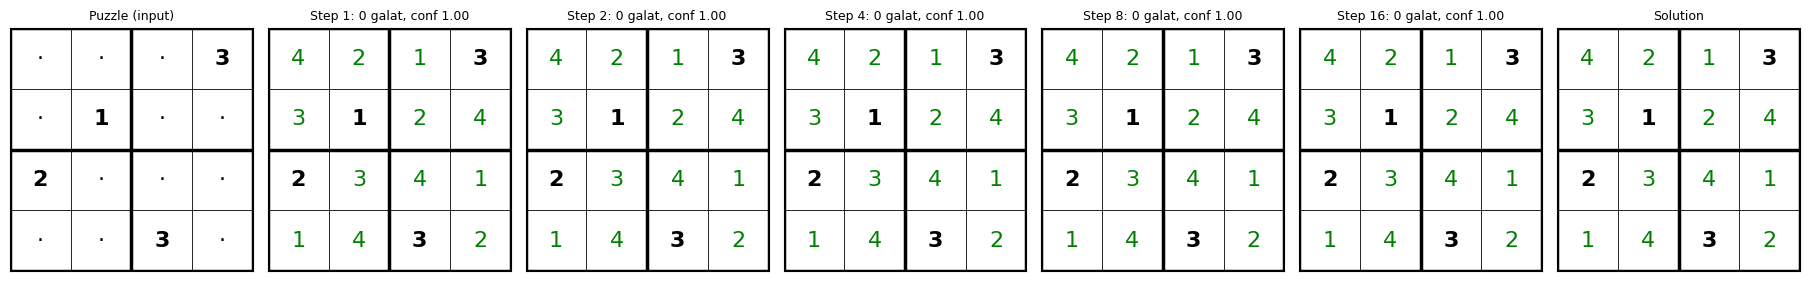

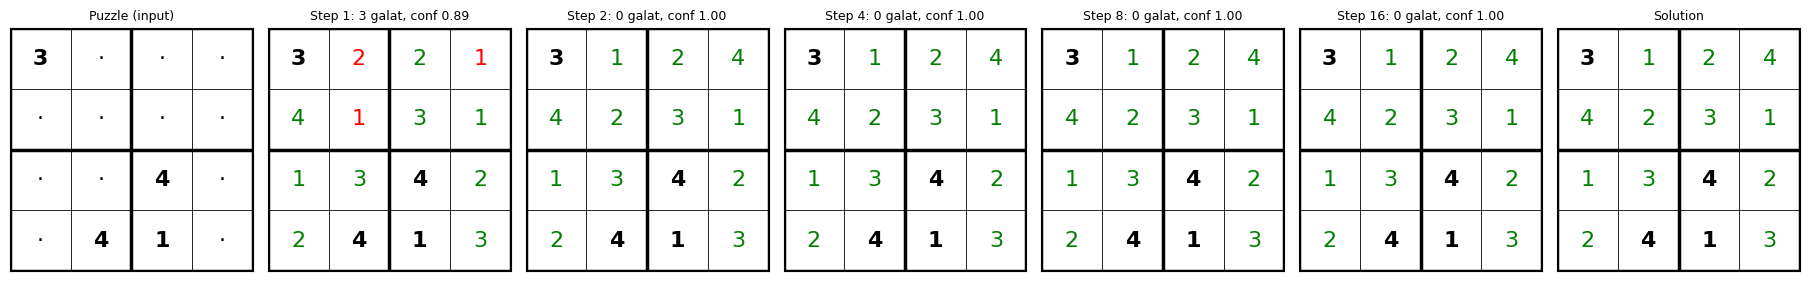

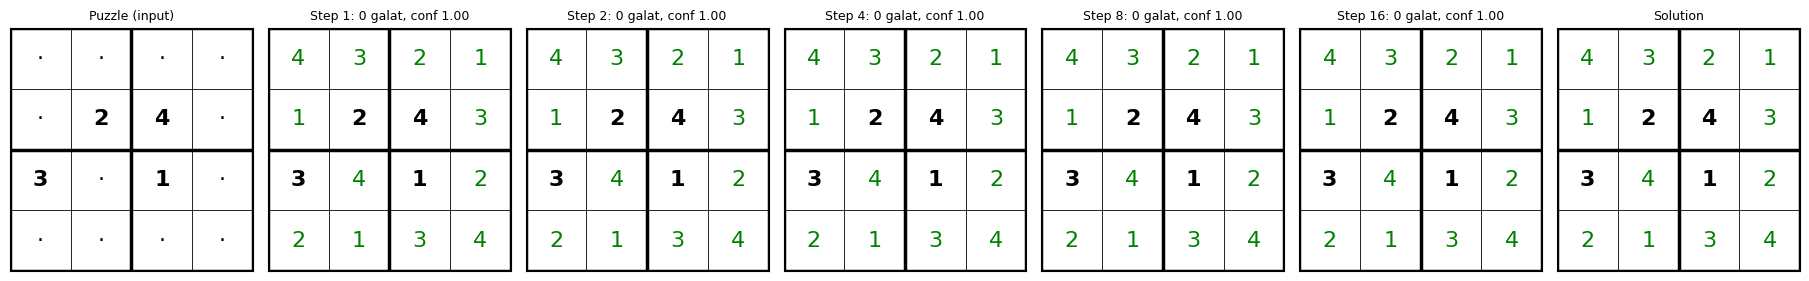

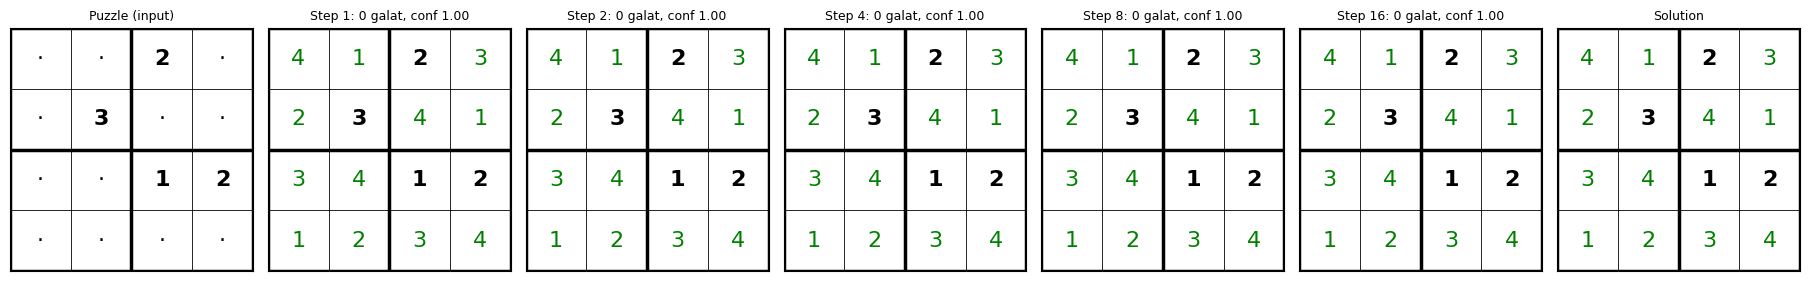

In [ ]:
import matplotlib.pyplot as plt

def draw(ax, g, puz, sol, title, N):
    b = int(N**0.5)
    ax.set_xlim(0, N); ax.set_ylim(N, 0); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    for i in range(N + 1):
        lw = 2.5 if i % b == 0 else 0.6
        ax.axhline(i, color='k', lw=lw); ax.axvline(i, color='k', lw=lw)
    for r in range(N):
        for c in range(N):
            k = r * N + c; v = int(g[k])
            if puz is not None and puz[k] != 0: col, w = 'black', 'bold'      # given clue
            elif sol is None:                   col, w = 'black', 'normal'
            else: col, w = ('green' if v == sol[k] else 'red'), 'normal'      # model ka guess
            ax.text(c + .5, r + .5, str(v) if v else '·', ha='center', va='center',
                    fontsize=16, color=col, fontweight=w)
    ax.set_title(title, fontsize=9)

def show_steps(ema, idx_list, n=6, T=3, N_sup=16, steps=(1, 2, 4, 8, 16), N=4, L=16, V=5):
    ev = TRM(L, V).to(dev); ev.load_state_dict(ema.sh); ev.eval()
    for idx in idx_list:
        puz, sol = Xte[idx:idx+1], Yte[idx:idx+1]
        preds = {}
        with torch.no_grad():
            x = ev.emb(puz); y = ev.y0.expand_as(x); z = ev.z0.expand_as(x)
            for s in range(1, N_sup + 1):
                y, z, lg, q = ev.deep_recursion(x, y, z, n, T)
                if s in steps:
                    preds[s] = (lg.argmax(-1)[0].cpu().numpy(), torch.sigmoid(q).item())
        P, S = puz[0].cpu().numpy(), sol[0].cpu().numpy()
        fig, axs = plt.subplots(1, len(steps) + 2, figsize=(2.6 * (len(steps) + 2), 3))
        draw(axs[0], P, P, None, 'Puzzle (input)', N)
        for a, s in zip(axs[1:-1], steps):
            g, conf = preds[s]
            nwrong = int((g != S).sum())
            draw(a, g, P, S, f'Step {s}: {nwrong} galat, conf {conf:.2f}', N)
        draw(axs[-1], S, P, S, 'Solution', N)
        plt.tight_layout(); plt.show()

show_steps(ema, idx_list=[0, 1, 2, 3])

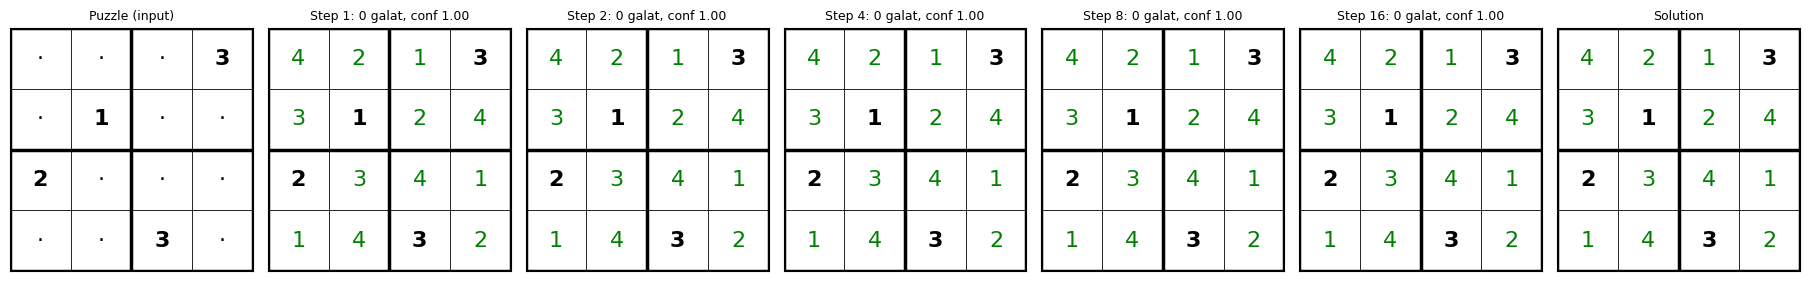

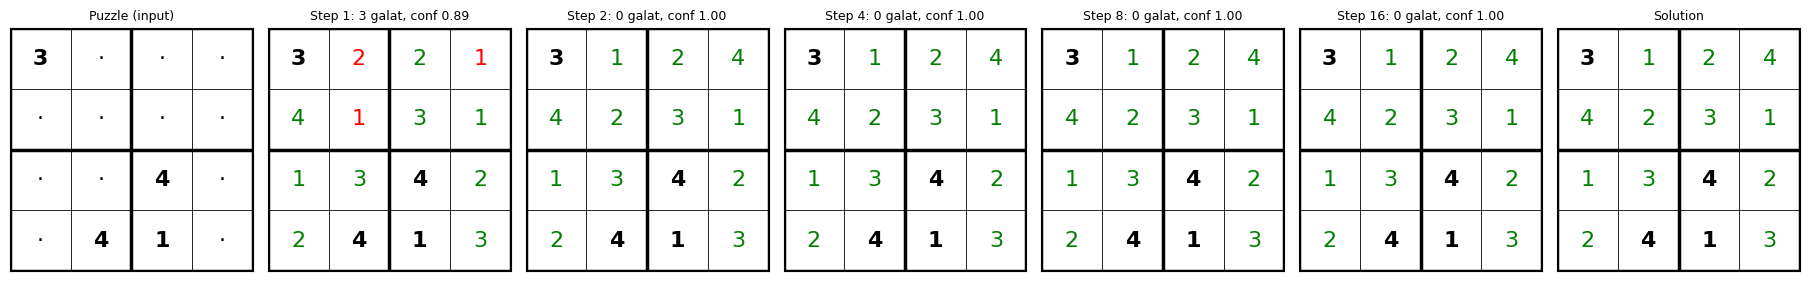

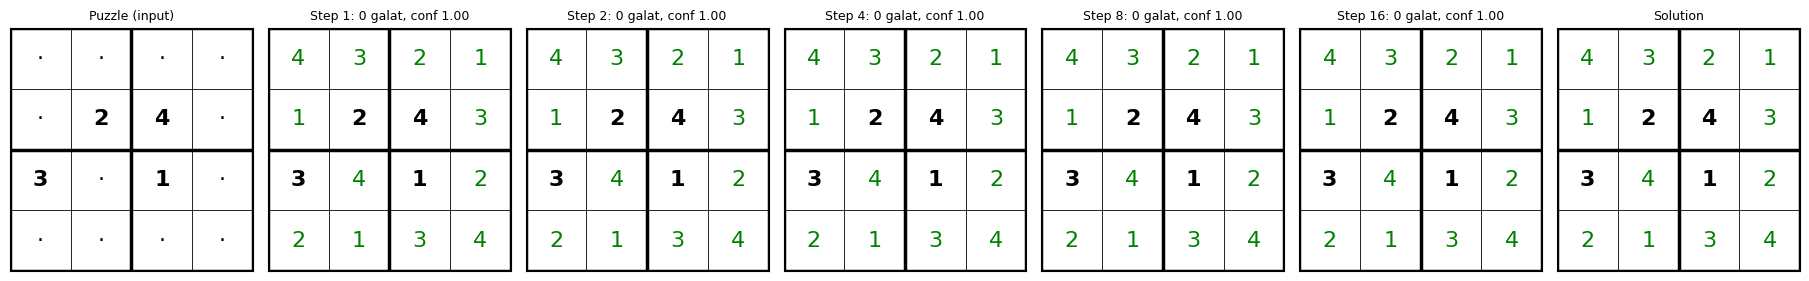

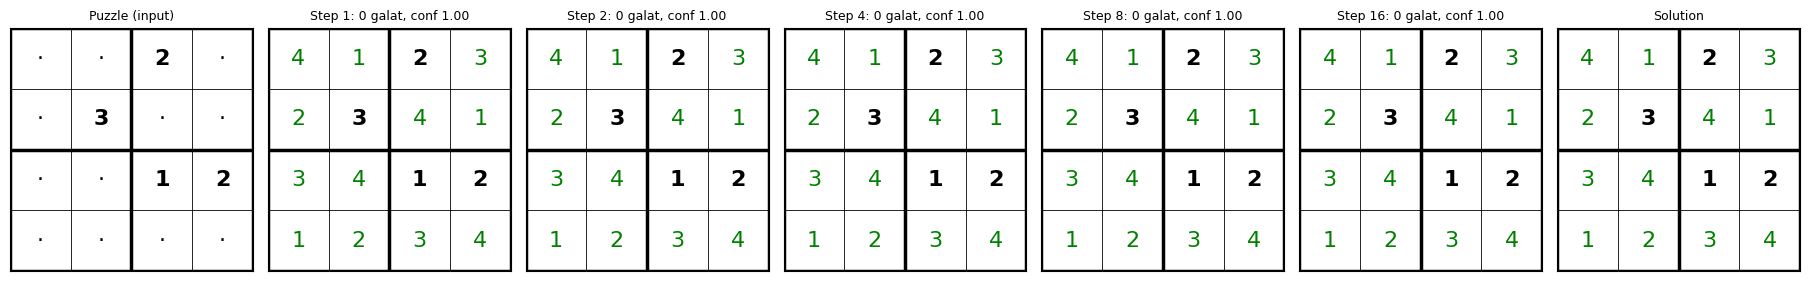

In [ ]:
import matplotlib.pyplot as plt

def draw(ax, g, puz, sol, title, N):
    b = int(N**0.5)
    ax.set_xlim(0, N); ax.set_ylim(N, 0); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    for i in range(N + 1):
        lw = 2.5 if i % b == 0 else 0.6
        ax.axhline(i, color='k', lw=lw); ax.axvline(i, color='k', lw=lw)
    for r in range(N):
        for c in range(N):
            k = r * N + c; v = int(g[k])
            if puz is not None and puz[k] != 0: col, w = 'black', 'bold'      # given clue
            elif sol is None:                   col, w = 'black', 'normal'
            else: col, w = ('green' if v == sol[k] else 'red'), 'normal'      # model ka guess
            ax.text(c + .5, r + .5, str(v) if v else '·', ha='center', va='center',
                    fontsize=16, color=col, fontweight=w)
    ax.set_title(title, fontsize=9)

def show_steps(ema, idx_list, n=6, T=3, N_sup=16, steps=(1, 2, 4, 8, 16), N=4, L=16, V=5):
    ev = TRM(L, V).to(dev); ev.load_state_dict(ema.sh); ev.eval()
    for idx in idx_list:
        puz, sol = Xte[idx:idx+1], Yte[idx:idx+1]
        preds = {}
        with torch.no_grad():
            x = ev.emb(puz); y = ev.y0.expand_as(x); z = ev.z0.expand_as(x)
            for s in range(1, N_sup + 1):
                y, z, lg, q = ev.deep_recursion(x, y, z, n, T)
                if s in steps:
                    preds[s] = (lg.argmax(-1)[0].cpu().numpy(), torch.sigmoid(q).item())
        P, S = puz[0].cpu().numpy(), sol[0].cpu().numpy()
        fig, axs = plt.subplots(1, len(steps) + 2, figsize=(2.6 * (len(steps) + 2), 3))
        draw(axs[0], P, P, None, 'Puzzle (input)', N)
        for a, s in zip(axs[1:-1], steps):
            g, conf = preds[s]
            nwrong = int((g != S).sum())
            draw(a, g, P, S, f'Step {s}: {nwrong} galat, conf {conf:.2f}', N)
        draw(axs[-1], S, P, S, 'Solution', N)
        plt.tight_layout(); plt.show()

show_steps(ema, idx_list=[0, 1, 2, 3])

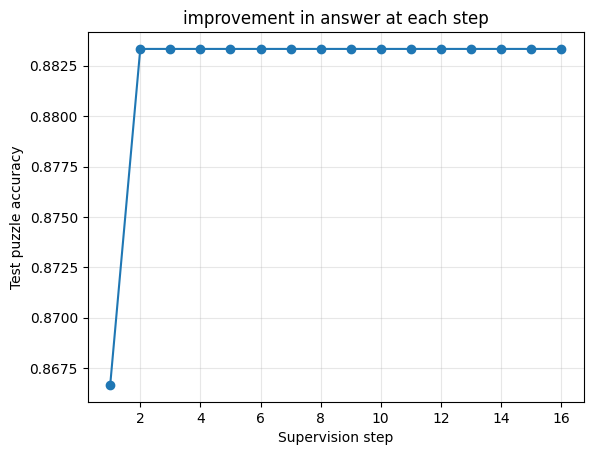

[0.867, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883, 0.883]


In [ ]:
@torch.no_grad()
def acc_vs_step(ema, n=6, T=3, N_sup=16, L=16, V=5):
    ev = TRM(L, V).to(dev); ev.load_state_dict(ema.sh); ev.eval()
    x = ev.emb(Xte); y = ev.y0.expand_as(x); z = ev.z0.expand_as(x); out = []
    for _ in range(N_sup):
        y, z, lg, _ = ev.deep_recursion(x, y, z, n, T)
        out.append((lg.argmax(-1) == Yte).all(1).float().mean().item())
    return out

curve = acc_vs_step(ema)
plt.plot(range(1, 17), curve, marker='o'); plt.xlabel('Supervision step'); plt.ylabel('Test puzzle accuracy')
plt.title('improvement in answer at each step'); plt.grid(alpha=.3); plt.show()
print([round(a, 3) for a in curve])

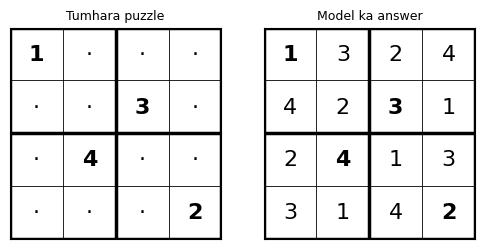

In [ ]:
def solve_custom(ema, grid, n=6, T=3, N_sup=16, N=4, L=16, V=5):
    ev = TRM(L, V).to(dev); ev.load_state_dict(ema.sh); ev.eval()
    puz = torch.tensor(grid).flatten().unsqueeze(0).to(dev)
    with torch.no_grad():
        x = ev.emb(puz); y = ev.y0.expand_as(x); z = ev.z0.expand_as(x)
        for _ in range(N_sup): y, z, lg, _ = ev.deep_recursion(x, y, z, n, T)
    g = lg.argmax(-1)[0].cpu().numpy()
    fig, axs = plt.subplots(1, 2, figsize=(6, 3))
    draw(axs[0], puz[0].cpu().numpy(), puz[0].cpu().numpy(), None, 'Tumhara puzzle', N)
    draw(axs[1], g, puz[0].cpu().numpy(), None, 'Model ka answer', N)
    plt.show()

solve_custom(ema, [[1,0,0,0],
                   [0,0,3,0],
                   [0,4,0,0],
                   [0,0,0,2]])

In [ ]:
# 1) deep_recursion ko replace karo (onestep option ke saath)
def deep_recursion(s, x, y, z, n, T, onestep=False):
    if onestep:   # HRM-style: sirf aakhri z aur y update me gradient
        with torch.no_grad():
            for _ in range(T - 1): y, z = s.latent_recursion(x, y, z, n)
            for _ in range(n - 1): z = s.net(x + y + z)
        z = s.net(x + y + z)
        y = s.net(y + z)
    else:         # TRM: poori aakhri recursion me gradient
        with torch.no_grad():
            for _ in range(T - 1): y, z = s.latent_recursion(x, y, z, n)
        y, z = s.latent_recursion(x, y, z, n)
    return y.detach(), z.detach(), s.head(y), s.qhead(y.mean(1)).squeeze(-1)
TRM.deep_recursion = deep_recursion

# 2) accuracy-vs-step curve kisi bhi model par
@torch.no_grad()
def curve_of(model, n, T, N_sup):
    model.eval()
    x = model.emb(Xte); y = model.y0.expand_as(x); z = model.z0.expand_as(x); out = []
    for _ in range(N_sup):
        y, z, lg, _ = model.deep_recursion(x, y, z, n, T)
        out.append((lg.argmax(-1) == Yte).all(1).float().mean().item())
    return out

# 3) runner: result Drive par JSON me save, resume-able
RES = '/content/drive/MyDrive/trm/results'; os.makedirs(RES, exist_ok=True)

def run_config(name, n=6, T=3, N_sup=16, seed=0, epochs=100, onestep=False, use_ema=True,
               L=16, V=5, bs=64, lr=1e-3):
    path = f'{RES}/{name}_s{seed}.json'
    if os.path.exists(path): return json.load(open(path))
    torch.manual_seed(seed); t0 = time.time()
    model = TRM(L, V).to(dev); ema = EMA(model)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=dev)
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i+bs]; puz, sol = Xtr[idx], Ytr[idx]
            y = model.y0.expand(len(idx), -1, -1); z = model.z0.expand(len(idx), -1, -1)
            for _ in range(N_sup):
                x = model.emb(puz)
                y, z, lg, q = model.deep_recursion(x, y, z, n, T, onestep)
                right = (lg.argmax(-1) == sol).all(1).float()
                loss = F.cross_entropy(lg.flatten(0, 1), sol.flatten()) \
                     + F.binary_cross_entropy_with_logits(q, right)
                opt.zero_grad(); loss.backward(); opt.step(); ema.update(model)
    ev = TRM(L, V).to(dev)
    ev.load_state_dict(ema.sh if use_ema else model.state_dict())
    curve = curve_of(ev, n, T, N_sup)
    r = dict(name=name, n=n, T=T, N_sup=N_sup, seed=seed, onestep=onestep, use_ema=use_ema,
             epochs=epochs, test_acc=curve[-1], curve=curve, minutes=(time.time() - t0) / 60)
    json.dump(r, open(path, 'w')); print(name, seed, round(r['test_acc'], 3), f"{r['minutes']:.1f} min")
    return r

In [ ]:
run_config('base', seed=0)

{'name': 'base',
 'n': 6,
 'T': 3,
 'N_sup': 16,
 'seed': 0,
 'onestep': False,
 'use_ema': True,
 'epochs': 100,
 'test_acc': 0.8320000171661377,
 'curve': [0.7920000553131104,
  0.8260000348091125,
  0.8280000686645508,
  0.8280000686645508,
  0.8300000429153442,
  0.8300000429153442,
  0.8300000429153442,
  0.8300000429153442,
  0.8320000171661377,
  0.8320000171661377,
  0.8320000171661377,
  0.8320000171661377,
  0.8320000171661377,
  0.8320000171661377,
  0.8320000171661377,
  0.8320000171661377],
 'minutes': 1.622393794854482}

In [ ]:
grid = [
  ('nsup1', dict(N_sup=1)), ('nsup2', dict(N_sup=2)),
  ('nsup4', dict(N_sup=4)), ('nsup8', dict(N_sup=8)),
  ('T1', dict(T=1)),        ('T2', dict(T=2)),
  ('n2', dict(n=2)),        ('n4', dict(n=4)),
  ('onestep', dict(onestep=True)), ('noema', dict(use_ema=False)),
]
for name, kw in grid:
    for seed in (0, 1, 2):
        run_config(name, seed=seed, **kw)
for seed in (1, 2): run_config('base', seed=seed)

nsup1 0 0.0 0.1 min
nsup1 1 0.0 0.1 min
nsup1 2 0.0 0.1 min
nsup2 0 0.0 0.2 min
nsup2 1 0.0 0.2 min
nsup2 2 0.0 0.2 min
nsup4 0 0.308 0.4 min
nsup4 1 0.283 0.4 min
nsup4 2 0.233 0.4 min
nsup8 0 0.858 0.8 min
nsup8 1 0.717 0.8 min
nsup8 2 0.425 0.8 min
T1 0 0.875 1.0 min
T1 1 0.808 1.0 min
T1 2 0.842 1.0 min
T2 0 0.833 1.3 min
T2 1 0.908 1.3 min
T2 2 0.925 1.3 min
n2 0 0.825 0.8 min
n2 1 0.917 0.8 min
n2 2 0.925 0.8 min
n4 0 0.85 1.2 min
n4 1 0.9 1.2 min
n4 2 0.892 1.2 min
onestep 0 0.842 1.1 min
onestep 1 0.767 1.1 min
onestep 2 0.917 1.1 min
noema 0 0.875 1.6 min
noema 1 0.85 1.6 min
noema 2 0.742 1.5 min
base 1 0.858 1.6 min
base 2 0.9 1.6 min


           acc    std  seeds   mins
name                               
T2       0.889  0.049      3  1.305
n2       0.889  0.055      3  0.758
n4       0.881  0.027      3  1.160
base     0.863  0.034      3  1.609
T1       0.842  0.033      3  1.037
onestep  0.842  0.075      3  1.113
noema    0.822  0.071      3  1.552
nsup8    0.667  0.221      3  0.788
nsup4    0.275  0.038      3  0.396
nsup1    0.000  0.000      3  0.101
nsup2    0.000  0.000      3  0.199


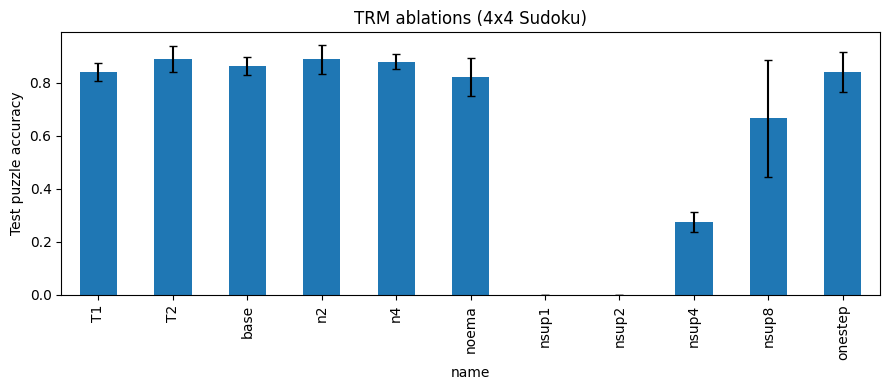

In [ ]:
import glob, pandas as pd
rows = [json.load(open(f)) for f in glob.glob(f'{RES}/*.json')]
df = pd.DataFrame(rows)
tab = df.groupby('name').agg(acc=('test_acc','mean'), std=('test_acc','std'),
                             seeds=('seed','count'), mins=('minutes','mean')).round(3)
print(tab.sort_values('acc', ascending=False))

tab['acc'].plot(kind='bar', yerr=tab['std'], figsize=(9,4), capsize=3)
plt.ylabel('Test puzzle accuracy'); plt.title('TRM ablations (4x4 Sudoku)')
plt.tight_layout(); plt.show()

In [ ]:
ctrl = [('nsup1_eq', dict(N_sup=1,  epochs=1600)),
        ('nsup2_eq', dict(N_sup=2,  epochs=800)),
        ('nsup4_eq', dict(N_sup=4,  epochs=400)),
        ('nsup8_eq', dict(N_sup=8,  epochs=200))]
for name, kw in ctrl:
    for seed in (0, 1, 2):
        run_config(name, seed=seed, **kw)

nsup1_eq 0 0.742 1.6 min
nsup1_eq 1 0.792 1.6 min
nsup1_eq 2 0.758 1.6 min
nsup2_eq 0 0.892 1.6 min
nsup2_eq 1 0.808 1.5 min
nsup2_eq 2 0.825 1.6 min
nsup4_eq 0 0.9 1.6 min
nsup4_eq 1 0.825 1.5 min
nsup4_eq 2 0.792 1.5 min
nsup8_eq 0 0.858 1.5 min
nsup8_eq 1 0.792 1.5 min
nsup8_eq 2 0.875 1.5 min


            acc    std  seeds   mins
name                                
T2        0.889  0.049      3  1.305
n2        0.889  0.055      3  0.758
n4        0.881  0.027      3  1.160
base      0.863  0.034      3  1.609
T1        0.842  0.033      3  1.037
onestep   0.842  0.075      3  1.113
nsup2_eq  0.842  0.044      3  1.561
nsup8_eq  0.842  0.044      3  1.538
nsup4_eq  0.839  0.055      3  1.545
noema     0.822  0.071      3  1.552
nsup1_eq  0.764  0.025      3  1.579
nsup8     0.667  0.221      3  0.788
nsup4     0.275  0.038      3  0.396
nsup1     0.000  0.000      3  0.101
nsup2     0.000  0.000      3  0.199


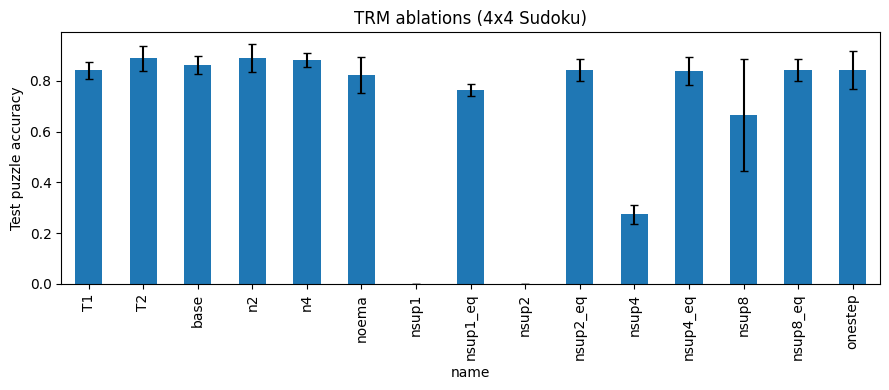

In [ ]:
import glob, pandas as pd
rows = [json.load(open(f)) for f in glob.glob(f'{RES}/*.json')]
df = pd.DataFrame(rows)
tab = df.groupby('name').agg(acc=('test_acc','mean'), std=('test_acc','std'),
                             seeds=('seed','count'), mins=('minutes','mean')).round(3)
print(tab.sort_values('acc', ascending=False))

tab['acc'].plot(kind='bar', yerr=tab['std'], figsize=(9,4), capsize=3)
plt.ylabel('Test puzzle accuracy'); plt.title('TRM ablations (4x4 Sudoku)')
plt.tight_layout(); plt.show()